# Augmentation và transfer learning

Khi chỉ có ít ảnh, ví dụ 60 ảnh chai nước, huấn luyện CNN từ đầu sẽ học thuộc. Có hai cách bù: augmentation (tạo thêm ảnh bằng cách lật, cắt, đổi độ sáng ảnh có sẵn) và transfer learning (dùng lại model đã học trên dữ liệu lớn). Cả hai đều có điều kiện: phép biến đổi không được làm đổi nhãn, ví dụ xoay ảnh số 6 thành số 9; và model cũ chỉ giúp được khi dữ liệu cũ đủ giống dữ liệu mới.

> **Mục tiêu**
>
> - Chọn phép augmentation không làm đổi nhãn.
> - Biến đổi ảnh cùng với box và mask.
> - Đo tác dụng của augmentation trên validation.
> - Chọn giữa feature extraction và fine-tuning.

## Dữ liệu nhiều hơn theo nghĩa nào?

Augmentation tạo một phiên bản biến đổi mỗi khi đọc mẫu: lật, crop, đổi sáng hoặc thêm nhiễu hợp lý. Nó không mang thêm thông tin độc lập như một buổi chụp mới; các phiên bản vẫn chung một nguồn. Vì vậy không được chia các bản biến đổi của cùng một ảnh sang cả train lẫn validation rồi coi chúng là các mẫu độc lập.



Gọi $T$ là phép biến đổi ảnh. Với classification, ta thường muốn $y(T(x))=y(x)$: nhãn không đổi. Với detection hay segmentation, đầu ra có tọa độ nên cần $y(T(x))=T(y(x))$: nhãn **cũng phải biến đổi**. Hai quan hệ này khác nhau. Lật ảnh chó vẫn là chó; lật biển chỉ hướng có thể đổi trái thành phải; xoay chữ số 6 có thể thành 9.

Crop còn tinh vi hơn. Nếu crop bỏ vật thể mà vẫn giữ nhãn “có chai”, ta tạo nhãn sai. Với nhãn cả ảnh như “phong cảnh”, một crop nhỏ có thể mất phần quyết định. Vì vậy mỗi augmentation là một giả định về điều kiện ứng dụng: phải xem ảnh sau biến đổi và hỏi đáp án còn đúng không.

**Hỏi nhanh.** Bài toán là phân biệt chữ “b” với chữ “d”. Lật ngang ảnh mà vẫn giữ nhãn cũ thì có ổn không?

- A. Ổn, vì lật ngang an toàn với mọi bài phân loại ảnh
- B. Ổn, nếu mỗi epoch chỉ lật một nửa số ảnh
- C. Không ổn, vì chữ “b” lật ngang trông như chữ “d”
- D. Không ổn, vì phép lật chỉ dùng được cho ảnh màu

<details><summary>Đáp án</summary>

C. Không ổn, vì chữ “b” lật ngang trông như chữ “d”

Ở bài này, nhãn chính là hướng của nét. Phép lật biến một mẫu “b” thành một mẫu “d” mà vẫn mang nhãn “b”. Lật ngang giữ nhãn với nhiều ảnh vật thể, nhưng không giữ được với ký tự. Lật một nửa số ảnh thì vẫn có một nửa số mẫu mang nhãn sai. Còn phép lật không phụ thuộc vào số kênh màu.

</details>

Các phép thường dùng chia thành ba nhóm. **Biến đổi hình học** (lật, crop, xoay, co giãn, dời) đổi vị trí điểm ảnh, nên với box, mask hay điểm mốc phải áp cùng phép lên nhãn. **Biến đổi cường độ** (độ sáng, tương phản, màu, làm mờ, nhiễu) giữ nguyên vị trí, nhưng có thể đụng vào chính tín hiệu của nhãn, như màu của quả chín hay độ sáng của vùng tổn thương trên phim X-quang. **Che và trộn mẫu**: Cutout xóa một ô chữ nhật và giữ nhãn; Mixup lấy $\tilde x=\lambda x_i+(1-\lambda)x_j$ và trộn hai nhãn one-hot thành $\tilde y=\lambda y_i+(1-\lambda)y_j$, với $\lambda\in(0,1)$ rút ngẫu nhiên; CutMix dán một mảnh của ảnh này lên ảnh kia và trộn nhãn theo tỉ lệ diện tích. Với nhãn mềm $\tilde y$, cross-entropy vẫn là $-\sum_k \tilde y_k\log p_k$. Ví dụ dán vùng $16 \times 16$ của ảnh chó vào ảnh mèo $32 \times 32$: mảnh chiếm $1/4$ diện tích nên nhãn là 0.75 mèo, 0.25 chó. Thêm nhiễu Gaussian nhỏ dạy model bền với nhiễu cảm biến; Cutout (random erasing) buộc model dùng nhiều phần của vật thay vì bám vào một chi tiết. Lật ngang ảnh có điểm mốc thì ngoài đổi tọa độ còn phải đổi tên: điểm “tay trái” thành “tay phải”.



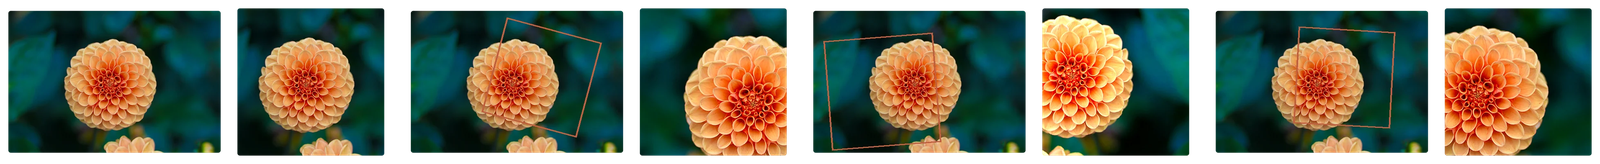

**Hỏi nhanh.** Model dự đoán tọa độ mắt trái và mắt phải trên ảnh chân dung rộng $W$. Khi lật ngang ảnh, ta đã đổi mọi tọa độ $x$ thành $W - x$. Nhãn còn thiếu bước nào?

- A. Đổi chỗ hai điểm, mắt trái thành mắt phải
- B. Không thiếu gì, vì tọa độ đã biến đổi theo ảnh
- C. Đổi thêm $y$ thành $H - y$ cho đối xứng
- D. Chia tọa độ cho $W$ để đưa về khoảng $[0, 1]$

<details><summary>Đáp án</summary>

A. Đổi chỗ hai điểm, mắt trái thành mắt phải

Ảnh lật là ảnh soi gương. Điểm từng là mắt trái giờ nằm ở chỗ của mắt phải trên một khuôn mặt bình thường. Giữ tên cũ thì model học rằng “mắt trái” lúc ở bên này, lúc ở bên kia. Vì vậy các thư viện ước lượng tư thế người khai báo sẵn những cặp điểm cần hoán đổi khi lật. Đổi $y$ là lật dọc, một phép khác. Chuẩn hóa tọa độ cũng không sửa được tên điểm.

</details>

## Ví dụ tính tay: lật box và mask

Ta dùng tọa độ biên liên tục `xyxy`: $[x_1,y_1,x_2,y_2]$, trong ảnh rộng $W$. Sau lật ngang, khoảng $[x_1,x_2]$ thành $[W-x_2,W-x_1]$. Với box $[1,2,4,6]$ và $W=10$, box mới là $[6,2,9,6]$. Độ rộng vẫn là 3. Quy ước điểm ảnh đóng ở hai đầu sẽ có công thức khác; phải xác nhận format trước khi dùng.

Ta kiểm với box và mask nhỏ. NumPy lật chiều cột; `.copy()` tạo mảng có bộ nhớ thông thường để chuyển sang tensor khi cần.

In [ ]:
import numpy as np

def flip_box_xyxy(box, width):
    x1, y1, x2, y2 = box
    return np.array([width - x2, y1, width - x1, y2])

mask = np.zeros((4, 10), dtype=np.uint8)
mask[1:3, 1:4] = 1
box = np.array([1, 1, 4, 3])
flipped_mask = np.flip(mask, axis=1).copy()
flipped_box = flip_box_xyxy(box, mask.shape[1])
print(flipped_box.tolist())
print(np.flatnonzero(flipped_mask[1]).tolist())
print(int(mask.sum()), int(flipped_mask.sum()))

[6, 1, 9, 3]
[6, 7, 8]
6 6


Mask mới sáng ở cột 6, 7, 8 và box chứa khoảng biên $[6,9]$. Số ô foreground không đổi. Nếu chỉ lật ảnh mà không lật mask, model sẽ bị yêu cầu tô vị trí không còn chứa vật thể.



Resize ảnh thường dùng bilinear; resize mask chứa ID lớp dùng nearest neighbor để không sinh ID phân số. Crop và xoay phải dùng cùng tham số hình học cho ảnh và nhãn. [TorchVision transforms v2](https://docs.pytorch.org/vision/stable/transforms.html) nhận ảnh, box và mask trong cùng một lời gọi và áp cùng tham số ngẫu nhiên cho tất cả; phép nào hợp lệ về nghĩa thì người dùng vẫn phải tự quyết. Với tensor `(C, H, W)`, lật ngang là `img.flip(-1)`. Xoay $90^\circ$ đổi chỗ hai cạnh: ảnh rộng 640, cao 480 thành rộng 480, cao 640. Khi crop cắt gần hết một vật, như box chỉ còn 10% diện tích trong vùng cắt, thường bỏ hẳn box ấy thay vì giữ một box gần như không còn vật.

**Hỏi nhanh.** Mask có ID lớp 0, 1 và 2. Resize bằng bilinear tạo ra giá trị 1.4 ở biên giữa vùng lớp 0 và vùng lớp 2. Như vậy có sao không?

- A. Không sao, ép về `long` thì 1.4 thành lớp 1 hợp lệ
- B. Không sao, biên đã có thêm một lớp trung gian thật
- C. Có, phải chuẩn hóa mask về $[0, 1]$ trước khi resize
- D. Có, ID lớp không nội suy được, nên phải dùng nearest

<details><summary>Đáp án</summary>

D. Có, ID lớp không nội suy được, nên phải dùng nearest

ID lớp là tên gọi, không phải cường độ. Trung bình của “nền” và “xe” không phải là “người”. Ép về `long` biến 1.4 thành 1, tức gán cho biên một lớp không hề có ở đó, và code không báo lỗi gì. Chuẩn hóa về $[0, 1]$ thì vẫn nội suy giữa các ID. Nearest neighbor chỉ chép lại ID có sẵn.

</details>

## Validation là ảnh ta thực sự sẽ gặp

Train dùng biến đổi ngẫu nhiên để model học bền hơn. Validation dùng preprocessing xác định để các thí nghiệm được so trong cùng điều kiện. Test-time augmentation (TTA) chạy model trên vài phiên bản của cùng một ảnh test, ví dụ ảnh gốc và ảnh lật, rồi lấy trung bình xác suất. TTA chỉ hợp lệ khi mọi phiên bản giữ nhãn; nó phải được thử trên validation, và thời gian suy luận nhân lên theo số phiên bản.



Với ảnh lấy từ video, theo người chụp hoặc theo thiết bị, ta chia theo nhóm nguồn. Random split theo frame gần nhau cho validation gần như bản sao của train, và augmentation không sửa được leakage này.

**Hỏi nhanh.** Model phân loại biển báo “rẽ trái” và “rẽ phải”. Một đội thêm TTA bằng cách lấy trung bình xác suất của ảnh gốc và ảnh lật ngang. Điểm sẽ thay đổi ra sao?

- A. Điểm tăng, vì TTA luôn giảm dao động của dự đoán
- B. Xác suất hai lớp bị kéo về gần nhau, điểm giảm
- C. Điểm không đổi, vì lúc train model đã gặp ảnh lật
- D. Điểm giữ nguyên, chỉ thời gian suy luận tăng gấp đôi

<details><summary>Đáp án</summary>

B. Xác suất hai lớp bị kéo về gần nhau, điểm giảm

Biển “rẽ trái” lật ngang chính là biển “rẽ phải”. Model tốt cho $p(\text{trái})$ cao ở ảnh gốc và $p(\text{phải})$ cao ở ảnh lật. Lấy trung bình thì ra gần 0.5 cho mỗi lớp, nên nhiều ảnh đổi dự đoán. TTA chỉ giảm dao động khi mọi phiên bản có cùng nhãn. Nếu lúc train cũng lật mà giữ nhãn, model còn tệ hơn nữa.

</details>

Một ablation dễ đọc có bốn cấu hình: baseline; baseline thêm phép A; baseline thêm phép B; cả hai. Giữ split, seed, số bước và metric; chỉ augmentation thay đổi. Validation nên có cả phần giống điều kiện train lẫn phần mô phỏng điều kiện mới mà model phải chịu được, vì một phép biến đổi có thể không đổi điểm ở phần này mà đổi mạnh ở phần kia. Mục sau làm đúng thí nghiệm ấy. Validation ở điều kiện mới cũng chỉ ra cần augmentation nào: ảnh train toàn ban ngày mà dùng thật cả ban đêm thì thêm ảnh đêm thật nếu có, hoặc mô phỏng tối, nhiễu, đổi màu cho train, rồi chấm trên ảnh đêm thật.

## Thí nghiệm: dời ảnh và lật ảnh chữ số

Bộ chữ số viết tay $8\times8$ có sẵn trong scikit-learn đủ nhỏ để chạy bốn cấu hình trên CPU. Ta lấy 300 ảnh làm train, phần còn lại làm validation. Validation có hai bản: ảnh gốc, và chính các ảnh đó bị dời 1 pixel theo một hướng ngẫu nhiên, như chữ viết lệch khỏi khung hay camera đặt lệch. Hai phép augmentation là dời 1 pixel, giữ nhãn vì chữ 2 dời sang phải vẫn là chữ 2, và lật ngang, giữ nguyên nhãn dù phần lớn chữ số lật xong không còn là chính nó. Bộ dữ liệu không kèm ID người viết, nên split ở đây ngẫu nhiên theo ảnh; cả bốn cấu hình dùng chung một split nên vẫn so được với nhau.

In [ ]:
import numpy as np
import torch
from torch import nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.set_num_threads(1)
digits = load_digits()
images = torch.tensor(digits.images / 16.0, dtype=torch.float32).unsqueeze(1)
labels = torch.tensor(digits.target)
train_ids, valid_ids = train_test_split(
    np.arange(len(labels)), train_size=300, stratify=digits.target, random_state=53)
train_x, train_y = images[train_ids], labels[train_ids]
valid_x, valid_y = images[valid_ids], labels[valid_ids]

MOVES = [(0, 1), (0, -1), (1, 0), (-1, 0)]   # (hàng, cột): phải, trái, xuống, lên

def shift(batch, dy, dx):
    """Dời ảnh dy hàng, dx cột; phần lộ ra điền 0, không cuộn vòng."""
    out = torch.zeros_like(batch)
    h, w = batch.shape[-2:]
    out[..., max(dy, 0):h + min(dy, 0), max(dx, 0):w + min(dx, 0)] = \
        batch[..., max(-dy, 0):h + min(-dy, 0), max(-dx, 0):w + min(-dx, 0)]
    return out

gen = torch.Generator().manual_seed(0)
move_of = torch.randint(0, 4, (len(valid_x),), generator=gen).tolist()
valid_moved = torch.stack([shift(x, *MOVES[k]) for x, k in zip(valid_x, move_of)])
versions = torch.stack([train_x] + [shift(train_x, *move) for move in MOVES])
print("train/valid:", len(train_x), len(valid_x))
print("versions:", tuple(versions.shape))

train/valid: 300 1497
versions: (5, 300, 1, 8, 8)


`versions` giữ sẵn năm phiên bản của mỗi ảnh train: nguyên bản và bốn hướng dời. Mỗi batch chọn ngẫu nhiên một phiên bản cho từng ảnh, nên mỗi epoch model gặp một tổ hợp khác. Cách này tương đương biến đổi lúc đọc mẫu, chỉ rẻ hơn vì phép dời ở đây có đúng năm khả năng.



Mỗi cấu hình train cùng một CNN nhỏ trong 60 epoch; mỗi dòng in trung bình accuracy của ba seed.

In [ ]:
def augment(rows, use_shift, use_flip, gen):
    if use_shift:     # mỗi ảnh: giữ nguyên hoặc một trong bốn hướng dời
        pick = torch.randint(0, 5, (len(rows),), generator=gen)
    else:
        pick = torch.zeros(len(rows), dtype=torch.long)
    x = versions[pick, rows]
    if use_flip:      # lật ngang khoảng một nửa số ảnh, nhãn giữ nguyên
        flip = torch.rand(len(rows), generator=gen) < 0.5
        x = torch.where(flip[:, None, None, None], x.flip(-1), x)
    return x

def accuracy(model, x, y):
    with torch.no_grad():
        return (model(x).argmax(dim=1) == y).float().mean().item()

def run(use_shift, use_flip, seed, epochs=60):
    torch.manual_seed(seed)
    model = nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(1), nn.Linear(32, 10))
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    gen = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        model.train()
        order = torch.randperm(len(train_x), generator=gen)
        for start in range(0, len(order), 50):
            rows = order[start:start + 50]
            loss = nn.functional.cross_entropy(
                model(augment(rows, use_shift, use_flip, gen)), train_y[rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return accuracy(model, valid_x, valid_y), accuracy(model, valid_moved, valid_y)

print("config          original  shifted")
for name, use_shift, use_flip in [("baseline", False, False), ("+ shift", True, False),
                                  ("+ flip", False, True), ("+ shift + flip", True, True)]:
    scores = np.array([run(use_shift, use_flip, seed) for seed in (1, 2, 3)])
    original, shifted = scores.mean(axis=0)
    print(f"{name:14s}  {original:8.3f}  {shifted:7.3f}")

config          original  shifted
baseline           0.888    0.627
+ shift            0.889    0.846
+ flip             0.843    0.564
+ shift + flip     0.779    0.722


Ở cột `original`, hai cấu hình gần như bằng nhau: 0.888 và 0.889. Chênh lệch này nhỏ hơn nhiều so với dao động khi đổi seed (đổi bộ seed có thể làm cột này nghiêng vài điểm theo chiều nào cũng được), nên cột ảnh gốc không cho biết phép dời giúp hay hại. Nếu validation chỉ có cột này, ta dễ kết luận phép dời vô ích. Cột `shifted` cho thấy điều ngược lại: 0.627 lên 0.846. Phép dời dạy model một bất biến mà validation gốc không hỏi tới. Lật ngang làm giảm cả hai cột (0.843 và 0.564), vì các chữ 2, 3, 4, 5, 6, 7, 9 sau khi lật không còn là chính chúng mà vẫn mang nhãn cũ. Ghép hai phép, phép lật ăn bớt phần lợi của phép dời: 0.722 so với 0.846 ở cột `shifted`. Augmentation không tự cộng dồn lợi ích; mỗi phép phải qua ablation riêng.



**Hỏi nhanh.** Một đội chỉ có validation gồm ảnh gốc. Baseline được 0.888, thêm phép dời được 0.889. Họ bỏ phép dời vì cho rằng nó không có tác dụng. Bạn thấy kết luận ấy thế nào?

- A. Hợp lý, phép dời không đổi điểm thì chỉ tốn thời gian train
- B. Hợp lý, nên thay bằng lật ngang cho điểm thay đổi rõ hơn
- C. Chưa đủ, cần thêm seed tới khi cột ảnh gốc tăng rõ rệt
- D. Chưa đủ, validation không có ảnh dời để đo đúng tác dụng ấy

<details><summary>Đáp án</summary>

D. Chưa đủ, validation không có ảnh dời để đo đúng tác dụng ấy

Phép dời nhắm tới ảnh lệch khung. Validation không có loại ảnh đó thì không thể thấy điểm ảnh dời tăng từ 0.627 lên 0.846. Thêm seed chỉ làm cột ảnh gốc chính xác hơn, không đưa điều kiện mới vào. Lật ngang làm điểm thay đổi rõ hơn thật, nhưng theo chiều giảm, vì nó làm sai nhãn chữ số.

</details>

## Transfer learning chuyển cái gì?

Encoder chuyển ảnh thành vector hoặc feature map; head chuyển biểu diễn đó thành nhãn của bài hiện tại. Transfer learning bắt đầu từ encoder đã học ở một nhiệm vụ nguồn, với giả định một phần đặc trưng có ích cho nhiệm vụ đích: cạnh và vân thường dùng lại được, còn ý nghĩa lớp và miền ảnh có thể khác.

Có ba mức thực hành. Feature extraction đóng băng encoder, chỉ train head mới. Fine-tuning mở một số block cuối hoặc toàn bộ encoder, thường với learning rate nhỏ hơn cho phần đã học. Train từ đầu bỏ lợi thế tri thức nguồn, nhưng là lựa chọn duy nhất khi đề cấm pretrained, và có thể hợp khi miền quá khác. Cơ chế đóng băng, learning rate riêng, BatchNorm và optimizer đã có ở bài 4.3; mục này bàn phần riêng của ảnh.

Hai câu hỏi định hướng lựa chọn: có bao nhiêu ảnh có nhãn, và ảnh đích giống ảnh nguồn đến đâu.

| | Miền gần nguồn (đồ vật chụp bằng điện thoại) | Miền xa nguồn (X-quang, siêu âm, ảnh vệ tinh) |
|---|---|---|
| Ít ảnh | Feature extraction làm mốc; mở thêm dễ học thuộc | Lấy đặc trưng ở block giữa, hoặc mở dần kèm augmentation |
| Nhiều ảnh | Mở block cuối hoặc toàn mạng, learning rate nhỏ | Mở nhiều block; so thêm với train từ đầu |

Bảng cho điểm xuất phát; validation quyết định. Lý do của cột bên phải: các block đầu học cạnh và vân nên vẫn dùng lại được, còn các block sau gắn với vật thể của tập nguồn nên ít hợp với miền mới.

Pretrained không tự động tốt hơn. Nếu nguồn là ảnh RGB tự nhiên, còn đích là ảnh xám rất nhỏ mà chi tiết một pixel quan trọng, resize và preprocessing có thể phá thông tin. Augmentation và transfer bổ sung cho nhau: khi fine-tune trên ít ảnh, augmentation hợp lệ giảm học thuộc; khi chỉ train head trên đặc trưng đã lưu, augmentation ngẫu nhiên mất tác dụng vì đặc trưng không được tính lại (bài 4.2).

**Hỏi nhanh.** Có 600 ảnh siêu âm có nhãn và một ResNet ImageNet. Lấy đặc trưng ở block cuối rồi train head thì validation thấp hơn nhiều so với kỳ vọng. Nên thử gì tiếp?

- A. Dùng đặc trưng của block giữa, hoặc mở thêm block encoder
- B. Bỏ pretrained, train ResNet-50 từ đầu trên đúng 600 ảnh này
- C. Giữ nguyên encoder, train head lâu gấp mười lần
- D. Đổi sang encoder ImageNet lớn hơn, vẫn chỉ lấy block cuối

<details><summary>Đáp án</summary>

A. Dùng đặc trưng của block giữa, hoặc mở thêm block encoder

Ảnh siêu âm rất khác ảnh ImageNet. Đặc trưng ở block cuối mã hóa vật thể của ImageNet, còn block giữa giữ cạnh và vân, những thứ dùng lại được. Mở thêm block thì encoder thích nghi được với miền mới. 600 ảnh quá ít để train ResNet-50 từ đầu. Head đã hội tụ thì train thêm trên cùng đặc trưng không thêm thông tin. Encoder lớn hơn từ cùng nguồn vẫn mang cùng khoảng cách ấy ở block cuối.

</details>

## Ảnh xám vào encoder ba kênh

Encoder ImageNet chờ ảnh RGB: conv đầu tiên có weight shape $(C_\text{out}, 3, k, k)$. Ảnh X-quang, ảnh nhiệt hay chữ số chỉ có một kênh. Cách đơn giản là chép kênh xám thành ba kênh giống nhau. Vì convolution tuyến tính theo đầu vào, khi cả ba kênh đều là $x$ thì

$$\sum_{c=1}^{3} W_c * x=\Big(\sum_{c=1}^{3} W_c\Big) * x,$$

tức một conv một kênh có weight bằng **tổng** ba lát weight theo kênh cho đúng cùng đầu ra. Với conv đầu của ResNet-18, weight giảm từ $64\times3\times7\times7=9408$ xuống $64\times1\times7\times7=3136$ số, và phép tính ở lớp đầu giảm ba lần. Đoạn sau kiểm đẳng thức trên bốn ảnh chữ số; `conv_rgb` khởi tạo ngẫu nhiên đóng vai conv đầu đã học, vì đẳng thức đúng với mọi giá trị weight.



In [ ]:
torch.manual_seed(53)
conv_rgb = nn.Conv2d(3, 8, 3, padding=1)     # đóng vai conv đầu của encoder RGB
conv_gray = nn.Conv2d(1, 8, 3, padding=1)
with torch.no_grad():
    conv_gray.weight.copy_(conv_rgb.weight.sum(dim=1, keepdim=True))
    conv_gray.bias.copy_(conv_rgb.bias)

gray = valid_x[:4]                              # bốn ảnh chữ số, shape (4, 1, 8, 8)
with torch.no_grad():
    out_repeat = conv_rgb(gray.repeat(1, 3, 1, 1))   # chép kênh xám thành ba kênh
    out_folded = conv_gray(gray)                     # một kênh, weight đã gộp
print("weight:", tuple(conv_rgb.weight.shape), "->", tuple(conv_gray.weight.shape))
print("output:", tuple(out_repeat.shape), tuple(out_folded.shape))
print("same output:", torch.allclose(out_repeat, out_folded, atol=1e-6))

weight: (8, 3, 3, 3) -> (8, 1, 3, 3)
output: (4, 8, 8, 8) (4, 8, 8, 8)
same output: True


Hai đầu ra cùng shape và trùng nhau đến sai số làm tròn. Hợp đồng đầu vào còn gồm chuẩn hóa: encoder ImageNet học trên ảnh đã trừ mean $(0.485, 0.456, 0.406)$ và chia std $(0.229, 0.224, 0.225)$ theo từng kênh. Chép kênh xám rồi chuẩn hóa từng kênh như lúc pretrain là cách giữ đúng hợp đồng; muốn gộp weight như trên thì phải xử lý thêm cả mean và std, nên chép kênh đơn giản và an toàn hơn. Kích thước cũng thuộc hợp đồng: ResNet giảm cạnh ảnh 32 lần, nên ảnh $28\times28$ chỉ còn bản đồ $1\times1$ ở block cuối. Phóng lên $224\times224$ cho block ấy bản đồ $7\times7$ nhưng không thêm chi tiết nào, và tốn gấp $64$ lần số điểm ảnh.

**Hỏi nhanh.** Để đưa ảnh xám vào ResNet ImageNet, một đội thay conv đầu bằng conv một kênh. Weight của nó là **trung bình** ba lát weight RGB. Mọi tầng sau giữ nguyên, và model được dùng ngay để lấy đặc trưng. So với cách chép kênh xám thành ba kênh, đầu ra của conv đầu khác thế nào?

- A. Giống hệt, vì trung bình và tổng chỉ khác tên gọi
- B. Nhỏ đi 3 lần, nhưng ReLU phía sau tự bù lại thang đo
- C. Phần trước bias nhỏ đi 3 lần, các tầng sau nhận sai thang
- D. Lớn lên 3 lần, vì bias cũng bị chia đều cho ba kênh

<details><summary>Đáp án</summary>

C. Phần trước bias nhỏ đi 3 lần, các tầng sau nhận sai thang

Chép kênh tương đương với lấy **tổng** ba lát weight. Trung bình bằng tổng chia 3, nên $W*x$ nhỏ đi 3 lần, còn bias giữ nguyên. Conv đầu của ResNet không có bias, nên cả đầu ra nhỏ đi 3 lần. ReLU không đổi thang, vì $\mathrm{ReLU}(a/3) = \mathrm{ReLU}(a)/3$. BatchNorm phía sau ở chế độ eval dùng running statistics cũ, nên cũng không bù. Fine-tune toàn mạng có thể học lại phần chênh, còn chỉ lấy đặc trưng thì không. Bias không bị chia.

</details>

## Thực hành với encoder ảnh có sẵn

Recipe [asset cục bộ](recipes/README.md) của chương nạp ResNet-18 từ một state dict ImageNet có sẵn trên máy, không tải từ Internet. Nó cần ba thứ: tệp checkpoint, tệp metadata ghi `sha256`, loại kiến trúc và 1000 tên lớp theo đúng thứ tự output, và một ảnh. Chạy không có `--run` chỉ kiểm điều kiện; có `--run` thì in lớp ImageNet có xác suất cao nhất cùng xác suất. Kết quả ấy là phép kiểm đường nạp: ảnh một đồ vật quen thuộc được gọi đúng tên cho thấy trọng số và preprocessing khớp nhau. Nó chưa phải model cho nhãn của bài; bước tiếp theo là thay `fc` bằng head đúng số lớp. Đừng dùng `weights=None` rồi gọi model là pretrained: đó là mạng ngẫu nhiên cho đến khi đã nạp trọng số.

Trình tự hợp lý là kiểm preprocessing trên vài ảnh, chạy feature extraction làm mốc, rồi mở block cuối kèm augmentation hợp lệ. Khi mở encoder, lưu cả model, head và mapping lớp; nạp lại ở tiến trình mới để kiểm. Ghi cả score và thời gian, vì fine-tuning hay TTA có thể vượt ngân sách thi.

**Hỏi nhanh.** Chạy recipe với một ảnh chai nước của câu lạc bộ, model in ra `water bottle 0.62`. Bài cần phân ba lớp là chai, cốc và hộp. Ta kết luận được gì?

- A. Model đã sẵn sàng, chỉ cần đọc ba lớp ImageNet gần nhất
- B. Đường nạp có vẻ đúng, nhưng vẫn cần head ba lớp và validation
- C. Trọng số chưa được nạp, vì model đã học sẽ cho xác suất trên 0.9
- D. Preprocessing sai, vì ảnh câu lạc bộ khác phân phối ImageNet

<details><summary>Đáp án</summary>

B. Đường nạp có vẻ đúng, nhưng vẫn cần head ba lớp và validation

Ra một tên lớp hợp nghĩa là dấu hiệu checkpoint và preprocessing khớp nhau. Nhưng output vẫn là 1000 lớp ImageNet, và “hộp” của bài có thể không ứng với lớp nào. Ánh xạ sang ba lớp phải được học bằng head mới, hoặc ít nhất được kiểm trên validation. Xác suất 0.62 không có nghĩa là trọng số chưa nạp: model đã học vẫn chia xác suất khi ảnh có nhiều đồ vật hay các lớp gần nhau. Preprocessing sai hiếm khi vẫn cho đúng tên đồ vật. Ảnh khác phân phối ImageNet cũng không phải lỗi preprocessing.

</details>

## Khi đi thi

- **Đọc luật về asset trước khi chọn hướng.** Đề có thể cấm mọi model pretrained, kể cả chỉ dùng kiến trúc từ thư viện, hoặc chỉ cấp sẵn vài checkpoint. Quyết định này đổi cả kế hoạch, nên xác nhận trước khi viết code.
- **Nhìn ảnh sau augmentation.** Lưu một grid vài chục ảnh kèm nhãn, box hoặc mask trước khi train lâu; nhãn sai do augmentation không hiện ra trong loss.
- **Validation giống điều kiện chấm.** Chia theo nguồn trước khi augment, giữ preprocessing validation xác định; nếu đề nói ảnh test chụp ở điều kiện khác, dựng thêm một phần validation mô phỏng điều kiện ấy.
- **Feature extraction trước, fine-tune sau.** Mốc head-only chạy nhanh và cho một submission an toàn; chỉ mở thêm block khi validation tăng thật.
- **Tính ngân sách cho TTA và fine-tuning.** Mỗi phiên bản TTA nhân thời gian forward; đo cả đọc ảnh, resize và model trên đúng phần cứng trước khi chọn số phiên bản.

## Tóm tắt

Augmentation mô tả các thay đổi mà đáp án phải chịu được; với tọa độ hay mask, nhãn biến đổi theo, còn Mixup và CutMix trộn cả nhãn. Lợi ích của một phép chỉ đo được trên validation chứa đúng điều kiện nó nhắm tới: trên chữ số, phép dời không đổi rõ điểm ảnh gốc nhưng nâng điểm ảnh dời 1 pixel từ 0.627 lên 0.846, còn phép lật làm sai nhãn và kéo cả hai cột xuống. Transfer learning bắt đầu từ biểu diễn đã học; chọn feature extraction hay fine-tuning theo lượng ảnh và độ gần miền, và đưa ảnh vào đúng hợp đồng đầu vào của encoder: số kênh, chuẩn hóa, kích thước.

## Kiểm tra cuối bài

**Câu 1.** Bài toán phân loại X-quang ngực có hay không có tràn dịch. Dấu hiệu bệnh là vùng phổi sáng hơn bình thường. Ảnh test chụp thẳng, lệch nhiều nhất khoảng 10°. Encoder là ResNet ImageNet. Pipeline train dưới đây có một bước có thể làm sai nhãn.
```py
train_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
```
Đó là bước nào?

- A. `Grayscale(3)`, vì chép một kênh thành ba kênh làm sai thông tin
- B. `RandomRotation(10)`, vì nó tạo tư thế phổi không có thật
- C. `ColorJitter`, vì đổi độ sáng có thể che đi hoặc tạo ra dấu hiệu bệnh
- D. `Normalize` theo ImageNet, vì phải tính mean và std riêng cho X-quang

<details><summary>Đáp án</summary>

C. `ColorJitter`, vì đổi độ sáng có thể che đi hoặc tạo ra dấu hiệu bệnh

Nhãn dựa vào độ sáng của vùng phổi. Tăng sáng 30% có thể làm phổi bình thường trông như tràn dịch, còn giảm sáng có thể xóa dấu hiệu thật. Nhãn sai như vậy mà loss không báo. Xoay tới 10° nằm trong khoảng của ảnh test thật. Chép kênh xám là cách giữ đầu vào ba kênh cho encoder. Chuẩn hóa theo ImageNet là điều encoder đã học quen. Tính mean và std riêng là một lựa chọn khác khi fine-tune, không làm sai nhãn.
Phỏng theo: [NOAI 2026 Singapore · Chung kết · Câu 12](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=17)

</details>

**Câu 2.** CNN phân loại ảnh X-quang xám $512\times 512$, pixel từ 0 đến 255. Có ba cách tiền xử lý. Cách A chia cho 255. Cách B trừ 127.5 rồi chia cho std tính trên toàn tập train. Cách C lấy mỗi ảnh trừ mean rồi chia std **của chính ảnh đó**. Trên validation, A được 82.3%, B được 84.7%, còn C được 79.1% và loss dao động. Vì sao C kém nhất?

- A. C cho đầu vào không có trung bình 0, nên BatchNorm mất ổn định
- B. C xóa khác biệt độ sáng giữa các phim, mà đó là thông tin chẩn đoán
- C. C nén dải giá trị khi ảnh không phủ hết 0–255, nên mất tương phản
- D. C dùng thống kê của toàn tập, nên rò thông tin validation vào train

<details><summary>Đáp án</summary>

B. C xóa khác biệt độ sáng giữa các phim, mà đó là thông tin chẩn đoán

Chuẩn hóa từng ảnh đưa mọi ảnh về cùng mean 0 và std 1. Một phim sáng toàn phần và một phim tối trở nên giống nhau, dù độ sáng ấy là thông tin chẩn đoán. Ảnh gần như một màu có std nhỏ, chia cho nó sẽ khuếch đại nhiễu, khớp với chuyện loss dao động. A và B áp cùng một phép biến đổi tuyến tính cho mọi ảnh, nên giữ được thứ tự độ sáng giữa các ảnh. C có trung bình 0 theo định nghĩa. Với ảnh không phủ hết 0–255, C giãn chứ không nén dải giá trị. C cũng không dùng thống kê của toàn tập.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 307](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=119)

</details>

**Câu 3.** Đề cho ảnh RGB $112\times 112$ nền trắng. Mỗi ảnh có đúng một hình, là hình tròn, tam giác hoặc chữ nhật, với vị trí, kích thước, góc xoay và màu bất kỳ. Tam giác không nhất thiết là tam giác đều. Chỉ có 200 ảnh có nhãn, và model phải tự dựng. Bộ augmentation nào giữ đúng nhãn?

- A. Xoay góc bất kỳ, lật, dời vị trí, đổi màu hình
- B. Co giãn riêng trục ngang theo tỉ lệ 2:1, đổi màu hình
- C. Random crop $40\times 40$ từ ảnh $112\times 112$, giữ nhãn cũ
- D. Cutout che một ô $56\times 56$ ở vị trí ngẫu nhiên, giữ nhãn cũ

<details><summary>Đáp án</summary>

A. Xoay góc bất kỳ, lật, dời vị trí, đổi màu hình

Đề đã nói vị trí, kích thước, góc và màu đều thay đổi tự do. Vì vậy xoay, lật, dời và đổi màu chỉ tạo thêm mẫu cùng phân phối. Vẫn nên xem grid, vì xoay cả ảnh có thể đẩy một hình sát mép ra ngoài khung. Co giãn một trục biến hình tròn thành elip, không còn là “tròn” nữa. Crop $40\times 40$ có thể bỏ mất cả hình, hoặc cắt tam giác thành tứ giác. Ô che $56\times 56$ có thể phủ kín một hình nhỏ, để lại ảnh trắng mà vẫn mang nhãn cũ.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2 · Problem 4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=7)

</details>

**Câu 4.** Một CNN train trên 500 ảnh đạt 99% accuracy trên train và 71% trên validation. Thêm augmentation hợp lệ, gồm crop nhẹ và đổi sáng nhẹ, thì train còn 93%, còn validation lên 78%. Augmentation đã giúp chủ yếu ở chỗ nào?

- A. Giảm overfit, vì dữ liệu train đa dạng hơn
- B. Train nhanh hơn, vì mỗi epoch model gặp ảnh dễ hơn
- C. Model nhỏ đi, vì có ít tham số phải ghi nhớ hơn
- D. Suy luận nhanh hơn, vì ảnh test được biến đổi trước

<details><summary>Đáp án</summary>

A. Giảm overfit, vì dữ liệu train đa dạng hơn

Khoảng cách giữa train và validation giảm từ 28 xuống 15 điểm. Điểm train giảm vì ảnh biến đổi khó học thuộc hơn. Augmentation không đổi số tham số, và mỗi epoch còn tốn thêm thời gian biến đổi ảnh. Validation và test dùng preprocessing xác định, nên thời gian suy luận không đổi.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 299](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=114)

</details>

**Câu 5.** Ba đội cùng dùng kiến trúc ResNet-18 cho 2000 ảnh lá cây. Đội A khởi tạo ngẫu nhiên rồi train toàn mạng. Đội B nạp trọng số ImageNet rồi train toàn mạng với learning rate nhỏ. Đội C nạp trọng số ImageNet, đóng băng encoder và chỉ train head. Đội nào đang dùng transfer learning?

- A. Chỉ C, vì B đã thay đổi hết trọng số ban đầu
- B. Chỉ B, vì C không cập nhật encoder
- C. B và C, vì cả hai đều bắt đầu từ trọng số đã học
- D. Cả ba, vì cùng dùng một kiến trúc đã công bố

<details><summary>Đáp án</summary>

C. B và C, vì cả hai đều bắt đầu từ trọng số đã học

Transfer learning là lấy trọng số đã học làm điểm xuất phát. Đóng băng encoder như C và fine-tune toàn mạng như B là hai mức của nó. Fine-tune không xóa những gì model đã học, các trọng số chỉ dịch chuyển dần từ điểm ấy. Kiến trúc giống nhau thì không mang theo tri thức nào, nên A là train từ đầu.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 205](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=75)

</details>

**Câu 6.** Mask rộng 8 pixel, các cột được đánh số từ 0 đến 7. Foreground nằm ở các cột 1, 2 và 3. Lật ngang thì foreground chuyển sang những cột nào?

- A. {4, 5, 6, 7}
- B. {4, 5, 6}
- C. {5, 6, 7}
- D. {1, 2, 3}

<details><summary>Đáp án</summary>

B. {4, 5, 6}

Với chỉ số pixel, cột $c$ thành cột $7 - c$: 1 thành 6, 2 thành 5, 3 thành 4. {5, 6, 7} là áp công thức $W - c$, vốn dành cho tọa độ liên tục của biên, vào chỉ số pixel. {4, 5, 6, 7} thừa một cột. {1, 2, 3} là quên lật.

</details>

**Câu 7.** Một đội sinh 10 bản augmentation cho mỗi ảnh, lưu chung một thư mục, rồi chia ngẫu nhiên 80/20 theo tệp. Validation đạt 0.99, nhưng trên ảnh mới chỉ được 0.71. Lý do khả dĩ nhất là gì?

- A. Các bản biến đổi của cùng một ảnh gốc nằm ở cả hai phía
- B. Model underfit, cần train thêm nhiều epoch nữa
- C. Augmentation quá yếu nên chưa chịu được ảnh mới
- D. Ảnh test của đề có nhiều nhãn bị gán sai

<details><summary>Đáp án</summary>

A. Các bản biến đổi của cùng một ảnh gốc nằm ở cả hai phía

Mỗi tệp validation có 9 “anh em” từ cùng một ảnh gốc. Xác suất cả 9 đều rơi vào validation chỉ cỡ $0.2^9 \approx 5\cdot 10^{-7}$. Gần như mọi ảnh validation có một bản gần trùng trong train, nên 0.99 chỉ đo khả năng nhận lại ảnh đã gặp. Underfit thì không thể đạt 0.99. Augmentation yếu hay nhãn test sai không giải thích được khoảng cách lớn ngay khi đổi sang ảnh mới. Cách sửa là chia theo ảnh gốc trước, augment sau.

</details>

**Câu 8.** Cấu hình không augmentation đạt 0.84 trên split tạo bằng seed 1. Cấu hình có augmentation đạt 0.88 trên split tạo bằng seed 2. Ta chắc chắn được điều gì?

- A. Augmentation tăng đúng 0.04 điểm trên mọi split
- B. Chưa tách được tác dụng của augmentation khỏi độ khó của split
- C. Augmentation tăng ít nhất 0.04 điểm, vì split 2 khó hơn
- D. Augmentation vô ích, vì chênh lệch nhỏ hơn 0.05

<details><summary>Đáp án</summary>

B. Chưa tách được tác dụng của augmentation khỏi độ khó của split

Hai split khác nhau thì độ khó khác nhau, nên chênh 0.04 là do cả hai nguyên nhân trộn lại. Không có thông tin nào cho biết split 2 khó hơn hay dễ hơn. Ngưỡng 0.05 là tùy ý. Cần chạy lại cả hai cấu hình trên cùng một split, tốt hơn nữa là vài seed.

</details>

**Câu 9.** Bài có 3 lớp. Mixup trộn ảnh mèo, lớp 0, với trọng số $\lambda = 0.7$ và ảnh chó, lớp 2, với trọng số $0.3$. Model dự đoán $p = (0.5,\ 0.1,\ 0.4)$ cho ảnh trộn. Cross-entropy của mẫu này bằng bao nhiêu?

- A. 0.485
- B. 0.693
- C. 0.755
- D. 0.760

<details><summary>Đáp án</summary>

D. 0.760

Nhãn trộn là $\tilde y = (0.7,\ 0,\ 0.3)$, nên loss bằng $-(0.7\ln 0.5 + 0.3\ln 0.4) = 0.485 + 0.275 = 0.760$. 0.693 là $-\ln 0.5$, coi ảnh như chỉ có mèo. 0.485 là quên số hạng của chó. 0.755 là $-\ln(0.7\cdot 0.5 + 0.3\cdot 0.4)$, tức trộn xác suất bên trong log.

</details>

**Câu 10.** Notebook nộp bài được chạy tối đa 20 phút. Đọc và resize toàn bộ ảnh test mất 5 phút, chỉ làm một lần rồi dùng chung cho mọi phiên bản. Mỗi lượt forward trên toàn bộ test mất 3 phút. Trên validation, TTA với 2, 4 và 8 phiên bản tăng điểm lần lượt 0.6, 0.8 và 0.9 so với không dùng TTA. Nên chọn bao nhiêu phiên bản?

- A. Không dùng TTA
- B. 2 phiên bản
- C. 4 phiên bản
- D. 8 phiên bản

<details><summary>Đáp án</summary>

C. 4 phiên bản

Với $k$ phiên bản, thời gian là $5 + 3k$ phút. $k = 4$ mất 17 phút, còn dư 3 phút. $k = 8$ mất 29 phút, vượt giới hạn dù điểm validation cao nhất. Chọn 2 là do tưởng phải đọc lại ảnh cho mỗi phiên bản, khi ấy 4 phiên bản mất $4\times(5 + 3) = 32$ phút. Không dùng TTA thì bỏ phí 0.8 điểm trong khi vẫn còn thời gian. Trước khi chốt, hãy đo lại trên máy chấm và chừa một ít thời gian dư.

</details>

## Đọc thêm

- [PyTorch — Transfer Learning for Computer Vision](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html): phân biệt train head cố định với fine-tuning; kiểm lại preprocessing của weights đang dùng.
- [TorchVision — Transforms](https://docs.pytorch.org/vision/stable/transforms.html): xem hỗ trợ ảnh, box, mask và cách dùng chung phép biến đổi hình học.
- [Dive into Deep Learning — Image Augmentation](https://d2l.ai/chapter_computer-vision/image-augmentation.html): đọc động cơ tăng biến thiên train, rồi đối chiếu với điều kiện giữ nhãn của bài.
- [Zhang và cộng sự — mixup: Beyond Empirical Risk Minimization (2018)](https://arxiv.org/abs/1710.09412): bài gốc của Mixup; đọc phần định nghĩa nhãn trộn và thí nghiệm với nhãn nhiễu.

Nguồn ảnh: ảnh tháp và ảnh hoa là ảnh mẫu `china.jpg` (danielbuechele, Flickr, CC BY 2.0) và `flower.jpg` (vultilion, Flickr, CC BY 2.0) kèm scikit-learn; ảnh chữ số lấy từ bộ `load_digits` của scikit-learn.